## 12. How far in advance can hypoxic events be predicted before the model stops outperforming a naive persistence baseline?


1. Data preparation
- Keep the 15-minute time grid and leave gaps as missing values.
- Exclude negative dissolved oxygen values and create lagged and rolling features.
- Include current and previous environmental measurements, including temperature.

In [ ]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from threadpoolctl import threadpool_limits

q1_eda = Path.cwd() if (Path.cwd() / 'Station_Transfer').is_dir() else Path.cwd() / 'EDA'
q1_folder = q1_eda / 'Station_Transfer'
assert q1_folder.is_dir(), 'Run from the repository root or the EDA directory.'
if str(q1_folder.resolve()) not in sys.path:
    sys.path.insert(0, str(q1_folder.resolve()))
import forecast_core as q1_core
import model_comparison as q1_experiment

q1_station = 'AEB'
q1_raw, q1_audit = q1_core.load_station(q1_folder / 'data' / f'{q1_station}.csv')

# clean the raw data according to the 'exclude_negative' policy
q1_data = q1_core.apply_do_policy(q1_raw, 'exclude_negative')

q1_features = q1_core.make_features(q1_data, 'combined')
q1_coverage = pd.DataFrame([
    {'Station': q1_station, 'Rows': q1_audit['source_rows'], 'Start': q1_audit['start'],
     'End': q1_audit['end'], 'Missing DO': q1_audit['missing_counts']['do'],
     'Negative DO': q1_audit['negative_counts']['do']}])
q1_coverage

,Station,Rows,Start,End,Missing DO,Negative DO
0,AEB,17664,2024-04-01 00:00:00,2024-10-01 23:45:00,3975,2769


In [ ]:
q1_core.describe_features(q1_features)

,Predictor,Meaning
0,do,Current DO (mg/L)
1,do_lag1,DO 15 minutes earlier (mg/L)
2,do_lag2,DO 30 minutes earlier (mg/L)
3,do_lag4,DO 60 minutes earlier (mg/L)
4,do_lag8,DO 120 minutes earlier (mg/L)
5,do_lag16,DO 240 minutes earlier (mg/L)
6,do_lag32,DO 480 minutes earlier (mg/L)
7,do_roll16_mean,Trailing 4-hour mean DO (mg/L)
8,do_roll96_mean,Trailing 24-hour mean DO (mg/L)
9,sal,Current Salinity (ppt)


## Build forecasting features

Features use current and lagged measurements only. The chronological split keeps the final 30% of rows for evaluation.


2. Models that we go to use and expirements that will beconducted.
- 1. Even though the data are time series, some data points are missed,
So, I will mainly focus on other models than RNN.  
- 2. Since problem is based a predicating values are continious, we use regression models and compete the performance.
 the regression models are Linear regression, Ridge regression, Quadratic Ridge, Decision tree, Random forest, Neural network. 
- 3. Consider, it is time series data with big gaps, we could consider Histogram gradient boosting. 
- 4. Since the problem is time sentive, we could like to try use models to predict DO in advances for different time ranges.

In [9]:
q1_names = {'linear': 'Linear (OLS)', 'ridge': 'Ridge', 'polynomial': 'Quadratic Ridge',
            'decision_tree': 'Decision tree', 'random_forest': 'Random forest',
            'hist_gbm': 'Histogram gradient boosting', 'mlp': 'Two-hidden-layer MLP'}
q1_fixed_settings = {
    'linear': 'OLS; no tuned parameter',
    'ridge': 'L2-regularized linear regression',
    'polynomial': 'Degree 2 + interactions; Ridge; 324 expanded terms',
    'decision_tree': 'Minimum leaf size 20; seed 0',
    'random_forest': '100 trees; minimum leaf 20; max_features 0.8; seed 0',
    'hist_gbm': '150 iterations; learning rate 0.05; L2 1; no internal early stopping',
    'mlp': 'Adam; ReLU; alpha 0.01; batch 256; 400-epoch cap; seed 0'}
pd.DataFrame([{'Model': q1_names[m], 'Fixed settings': q1_fixed_settings[m],
               'Validation candidates': json.dumps(q1_core.CONFIGS[m])}
              for m in q1_experiment.PRIMARY_MODELS])

,Model,Fixed settings,Validation candidates
0,Linear (OLS),OLS; no tuned parameter,[{}]
1,Ridge,L2-regularized linear regression,"[{""alpha"": 1.0}, {""alpha"": 100.0}]"
2,Quadratic Ridge,Degree 2 + interactions; Ridge; 324 expanded t...,"[{""alpha"": 1.0}, {""alpha"": 100.0}]"
3,Decision tree,Minimum leaf size 20; seed 0,"[{""max_depth"": 5}, {""max_depth"": 10}]"
4,Random forest,100 trees; minimum leaf 20; max_features 0.8; ...,"[{""max_depth"": 8}, {""max_depth"": null}]"
5,Histogram gradient boosting,150 iterations; learning rate 0.05; L2 1; no i...,"[{""max_leaf_nodes"": 7}, {""max_leaf_nodes"": 15}]"
6,Two-hidden-layer MLP,Adam; ReLU; alpha 0.01; batch 256; 400-epoch c...,"[{""hidden_layer_sizes"": [32, 16]}, {""hidden_la..."


b. Traing and testing

In [10]:
q1_split_rows = []
for q1_hours in q1_core.HORIZONS:
    _, q1_target_times, q1_train, q1_test = q1_core.split_masks(
        q1_data, q1_hours, q1_experiment.CUTOFF)
    assert q1_target_times[q1_train].max() < q1_data.index[q1_test].min()
    q1_split_rows.append({'Station': q1_station, 'Lead (h)': q1_hours,
                          'Training cases': int(q1_train.sum()),
                          'Evaluation cases': int(q1_test.sum()),
                          'Last training target': q1_target_times[q1_train].max(),
                          'First evaluation origin': q1_data.index[q1_test].min()})
pd.DataFrame(q1_split_rows)

,Station,Lead (h),Training cases,Evaluation cases,Last training target,First evaluation origin
0,AEB,1,8186,2167,2024-07-25 09:15:00,2024-08-08 16:15:00
1,AEB,3,7999,2089,2024-07-25 09:15:00,2024-08-08 16:15:00
2,AEB,6,7861,2013,2024-07-25 09:15:00,2024-08-08 16:15:00
3,AEB,12,7667,1916,2024-07-25 09:15:00,2024-08-08 16:15:00
4,AEB,24,7393,1675,2024-07-25 00:00:00,2024-08-08 16:30:00


In [ ]:
q1_policy = 'exclude_negative'
q1_input_set = 'combined'
q1_run_full_experiment = True
q1_metrics_path = q1_folder / 'results' / 'single_station' / q1_station / 'train_test_metrics.csv'

if q1_run_full_experiment:
    import importlib
    importlib.reload(q1_core)
    importlib.reload(q1_experiment)
    with threadpool_limits(limits=2):
        q1_metrics = q1_experiment.train_and_evaluate(q1_folder.resolve(), q1_station)
else:
    if not q1_metrics_path.is_file():
        raise FileNotFoundError(
            f'No saved single-station metrics at {q1_metrics_path}. '
            'Set q1_run_full_experiment = True and rerun this cell to train the models.'
        )
    q1_metrics = pd.read_csv(q1_metrics_path)
    print(f'Loaded single-station metrics from {q1_metrics_path}')
if 'r2' not in q1_metrics.columns:
    raise ValueError('Saved metrics do not contain R2. Restart the kernel, set q1_run_full_experiment = True, and rerun this cell.')

Fitted exclude_negative, AEB, 1h (60 cumulative fits)
Fitted exclude_negative, AEB, 3h (120 cumulative fits)
Fitted exclude_negative, AEB, 6h (180 cumulative fits)
Fitted exclude_negative, AEB, 12h (240 cumulative fits)
Fitted exclude_negative, AEB, 24h (300 cumulative fits)
Fitted clip_zero, AEB, 1h (360 cumulative fits)
Fitted clip_zero, AEB, 3h (420 cumulative fits)
Fitted clip_zero, AEB, 6h (480 cumulative fits)
Fitted clip_zero, AEB, 12h (540 cumulative fits)
Fitted clip_zero, AEB, 24h (600 cumulative fits)
Completed 600 fits; 220 metric rows.


c. Performance measurements

Training scores are in-sample and can look optimistic; test scores use held-out future rows. The plots compare RMSE, MAE, R2, precision, recall, and F1 across forecast horizons for the station, cleaning policy, and input set selected above. Hypoxia means DO below 2 mg/L; undefined metrics are left blank.

,horizon_hours,model,split,n,rmse,mae,r2
12,1,decision_tree,test,2167,0.613438,0.418235,0.931727
4,1,decision_tree,train,8186,0.640872,0.462674,0.947089
14,1,hist_gbm,test,2167,0.629650,0.449438,0.928071
6,1,hist_gbm,train,8186,0.589738,0.431873,0.955196
9,1,linear,test,2167,0.673048,0.468562,0.917813
...,...,...,...,...,...,...,...
91,24,polynomial,train,7393,1.700984,1.257659,0.638477
101,24,random_forest,test,1675,2.454068,1.924434,-0.061844
93,24,random_forest,train,7393,1.092692,0.813098,0.850813
98,24,ridge,test,1675,4.403978,3.103113,-2.419618


,horizon_hours,model,split,n,precision,recall,f1
12,1,decision_tree,test,2167,0.898348,0.879353,0.888749
4,1,decision_tree,train,8186,0.923445,0.909152,0.916243
14,1,hist_gbm,test,2167,0.874690,0.876866,0.875776
6,1,hist_gbm,train,8186,0.926962,0.913863,0.920366
9,1,linear,test,2167,0.884664,0.868159,0.876334
...,...,...,...,...,...,...,...
91,24,polynomial,train,7393,0.801180,0.691886,0.742533
101,24,random_forest,test,1675,0.546429,0.301775,0.388818
93,24,random_forest,train,7393,0.849242,0.812623,0.830529
98,24,ridge,test,1675,0.504032,0.246548,0.331126


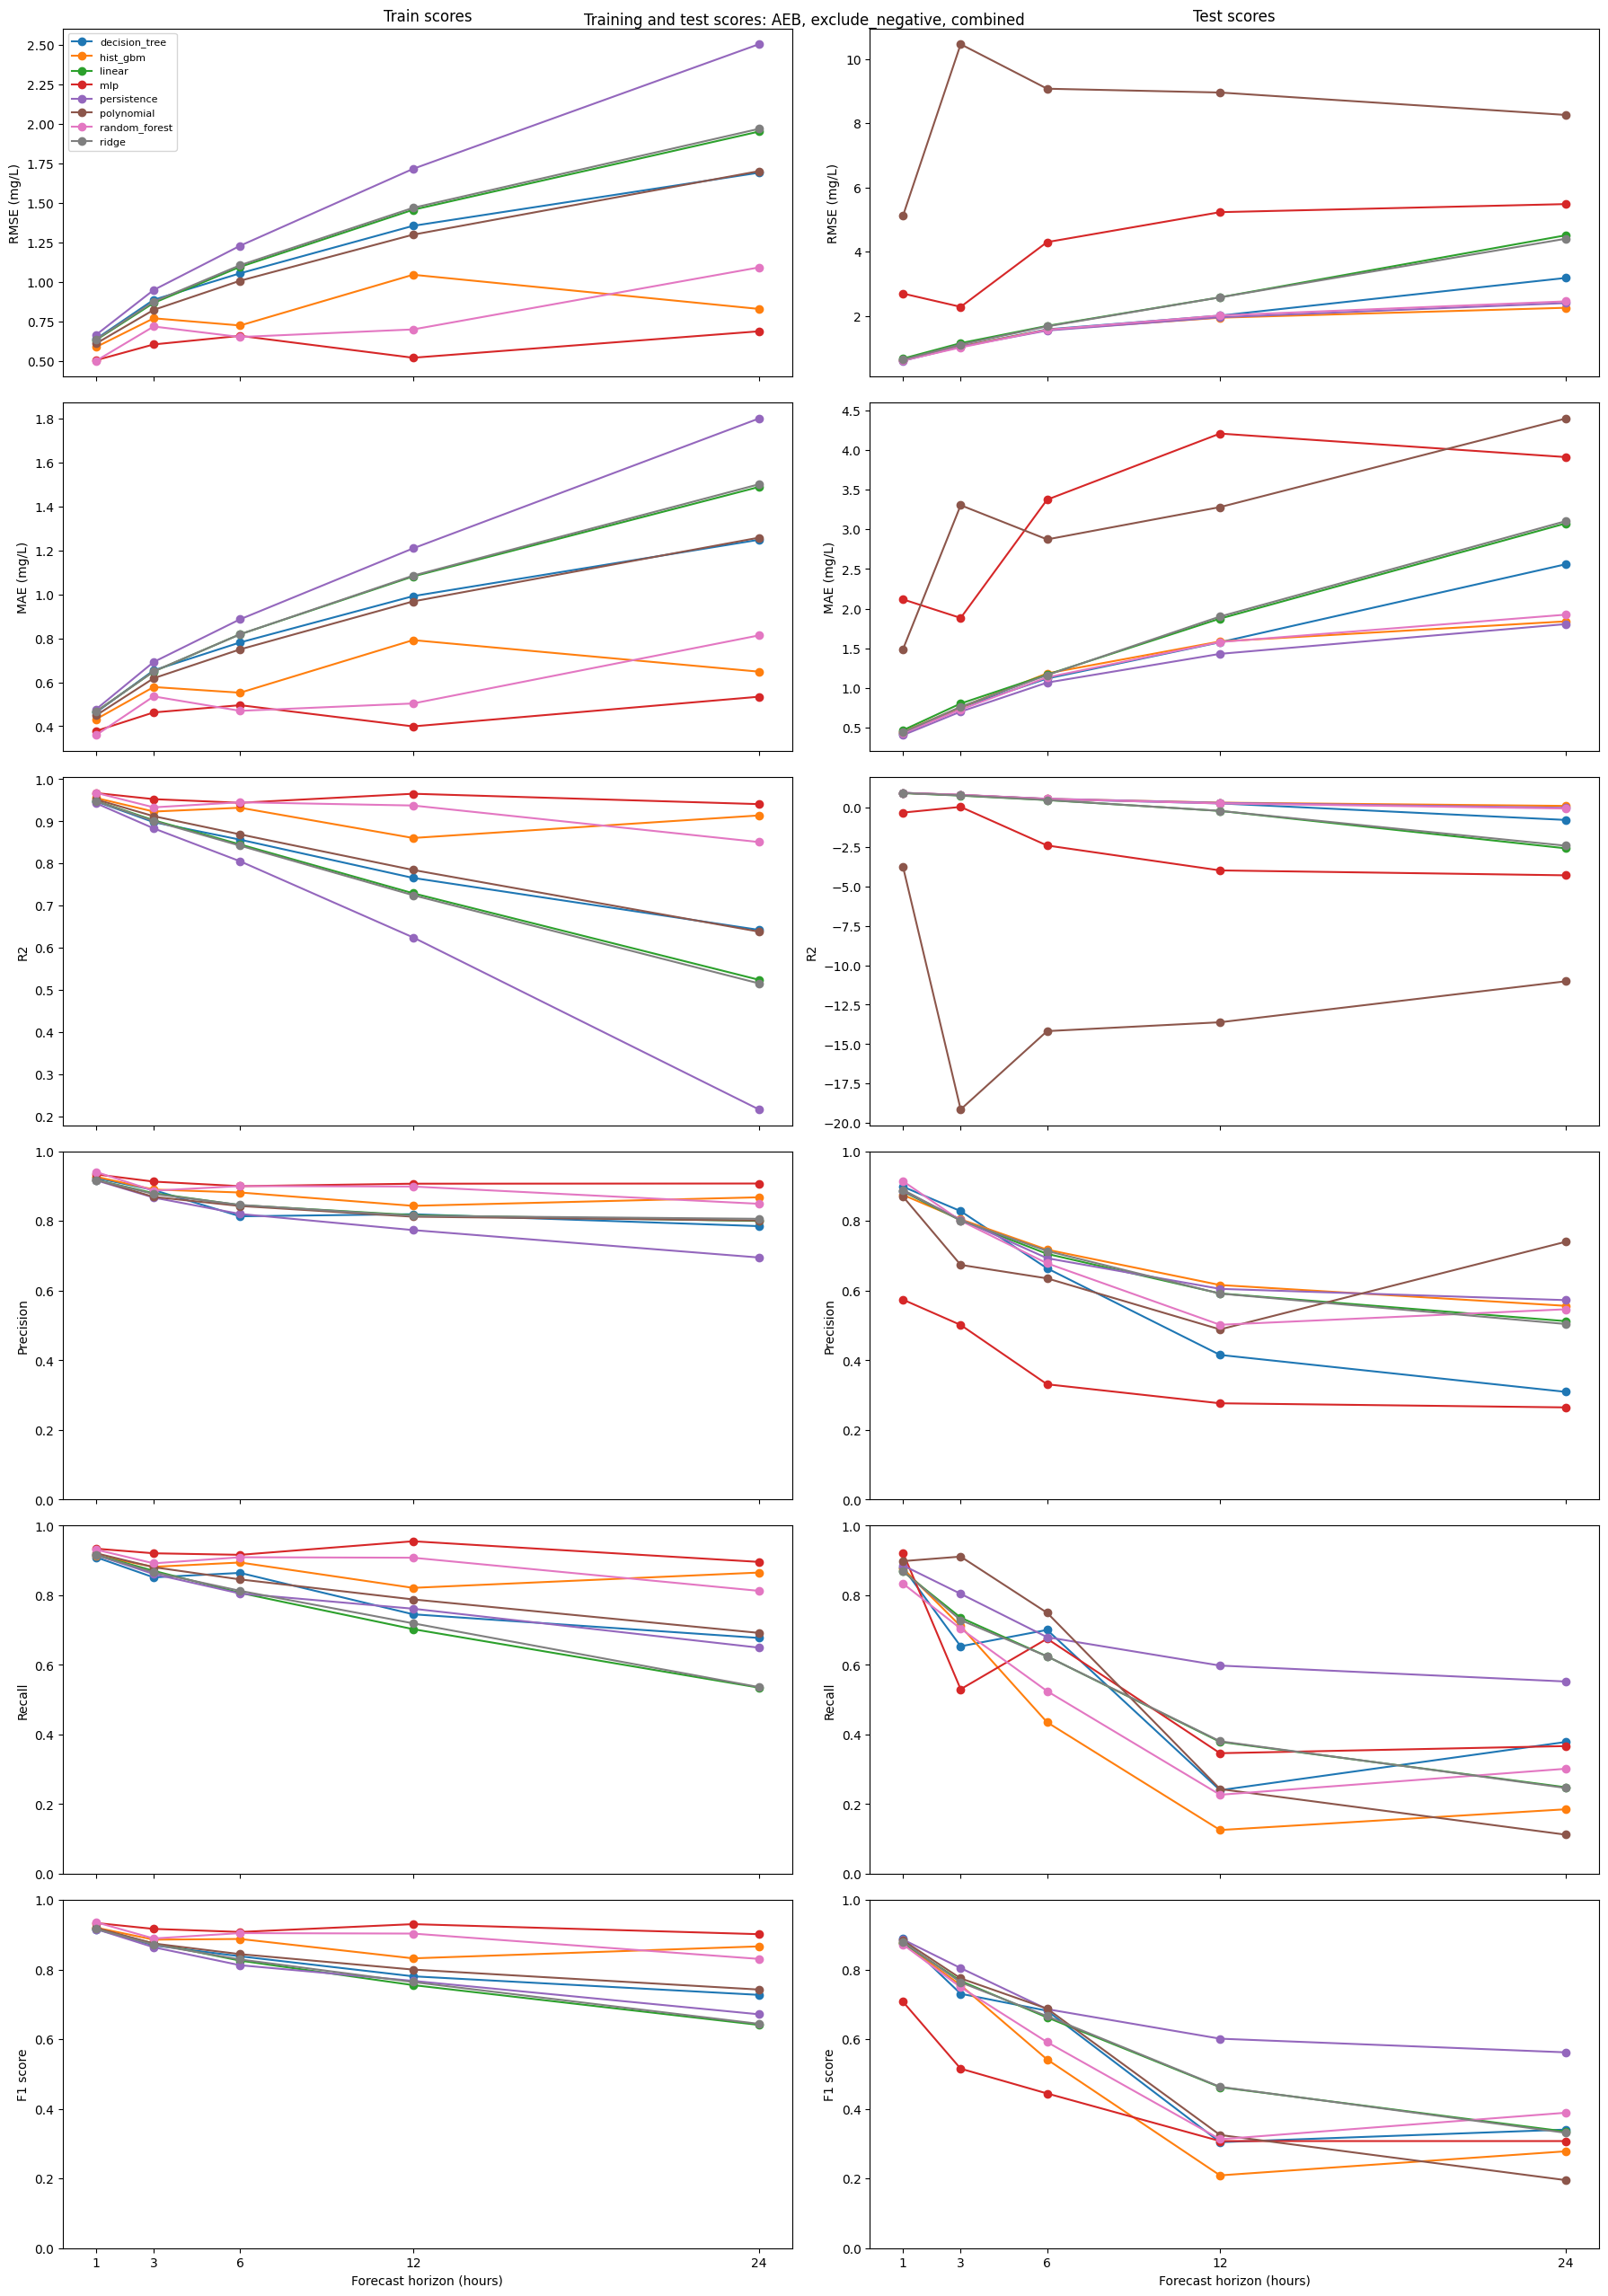

In [ ]:
scores_df = q1_metrics.loc[
    (q1_metrics['station'] == q1_station)
    & (q1_metrics['policy'] == q1_policy)
    & (q1_metrics['input_set'] == q1_input_set)
].sort_values(['horizon_hours', 'model', 'split']).copy()
if scores_df.empty:
    raise ValueError(f'No metrics for {q1_station}, {q1_policy}, {q1_input_set}.')
if scores_df.duplicated(['horizon_hours', 'model', 'split']).any():
    raise ValueError('Multiple metric rows for a horizon, model, and split.')

display(scores_df[['horizon_hours', 'model', 'split', 'n', 'rmse', 'mae', 'r2']])
display(scores_df[['horizon_hours', 'model', 'split', 'n', 'precision', 'recall', 'f1']])

horizon_order = sorted(scores_df['horizon_hours'].unique())
model_order = scores_df['model'].unique()
plot_specs = [
    ('rmse', 'RMSE (mg/L)', None),
    ('mae', 'MAE (mg/L)', None),
    ('r2', 'R2', None),
    ('precision', 'Precision', (0, 1)),
    ('recall', 'Recall', (0, 1)),
    ('f1', 'F1 score', (0, 1)),
]
fig, axes = plt.subplots(len(plot_specs), 2, figsize=(18, 26), sharex=True)
for row_index, (metric, ylabel, ylim) in enumerate(plot_specs):
    for col_index, split_name in enumerate(['train', 'test']):
        ax = axes[row_index, col_index]
        for model_name in model_order:
            subset = scores_df[
                (scores_df['split'] == split_name) & (scores_df['model'] == model_name)
            ].sort_values('horizon_hours')
            ax.plot(subset['horizon_hours'], subset[metric], marker='o', label=model_name)
        ax.set_ylabel(ylabel)
        if ylim is not None:
            ax.set_ylim(*ylim)
        if row_index == 0:
            ax.set_title(f'{split_name.title()} scores')
        if row_index == 0 and col_index == 0:
            ax.legend(fontsize=8)
        if row_index == len(plot_specs) - 1:
            ax.set_xlabel('Forecast horizon (hours)')
            ax.set_xticks(horizon_order)
fig.suptitle(f'Training and test scores: {q1_station}, {q1_policy}, {q1_input_set}')
fig.tight_layout()
plt.show()

d. Conclusion

1. Generally overfitting in all models.

2. Regression performance scores
The training results show that almost all models outperform the persistence baseline, which has higher RMSE values. Higher RMSE indicates worse performance. As the prediction horizon increases, the RMSE values also increase. However, the test results show the opposite trend in terms of relative model performance.

3. Classification performance 
For the training dataset, almost all models outperform the persistence baseline in predicting hypoxia events, with the baseline showing lower F1 scores. However, for the test dataset, the results show the opposite trend. 